# Bifurcación de canales — Formulación I: flujo plano ideal (Milne-Thomson, §10.8)
## Trabajo 01 · Estructura N.º 8 · Fase I

**Curso:** Flujo en superficie libre — UNSCH, Unidad de Posgrado
**Fuente de la formulación:** Milne-Thomson, L. M., *Theoretical Hydrodynamics* (reimpresión Dover), §10·8 «Branch in a canal», pp. 279–280 (el número de edición y año se confirman en el ejemplar).

Este cuaderno plantea el reparto de velocidades y caudales en una bifurcación como un **sistema de ecuaciones no lineales** $\mathbf F(\mathbf X)=\mathbf 0$ y lo resuelve con **código propio** (Newton–Raphson amortiguado, sin `scipy`). Incluye la derivación resumida del libro, el jacobiano analítico, la estrategia de valor inicial con garantía de raíz única, una verificación preliminar y la lectura física del resultado.

**Alcance de la Fase I:** formulación, algoritmo y resultados. La verificación formal (tres pruebas documentadas) corresponde a la Fase II, y el contraste con el modelo 2D a la Fase IV.

## 1. Planteamiento del problema

Un canal principal de ancho $h$, con velocidad uniforme $U$ lejos aguas arriba, se divide en un **canal principal aguas abajo** de ancho $h_1$ (velocidad $U_1$) y un **ramal** de ancho $h_2$ (velocidad $U_2$). Las paredes del ramal forman un ángulo $\alpha$ con las del canal principal, medido en el punto $C$ desde la pared aguas abajo (el mismo $\theta$ que usan Gumgum y otros autores). Se busca determinar $U_1$ y $U_2$.

En el esquema del libro (Fig. 10·8 (i)) el punto $C$ es la esquina aguas abajo del ramal, donde la velocidad es nula (estancamiento), y el punto $E$ es la esquina aguas arriba del ramal, donde el modelo da velocidad infinita. La línea de corriente $l$ que llega desde el infinito se divide en $C$: el fluido a su izquierda entra al ramal y el de su derecha sigue por el canal principal.

**Hipótesis del modelo (y su rango de validez):**

1. Flujo **plano, permanente, irrotacional** de fluido **ideal** (sin viscosidad ni fricción).
2. Canales rectos con paredes paralelas y **semiinfinitos**: la velocidad es uniforme en $-\infty$ (canal principal) y en $+\infty$ (canal aguas abajo y ramal).
3. El flujo se supone adherido a las paredes (**sin separación**). En $E$ el modelo da velocidad infinita (singularidad) y en $C$ velocidad nula.
4. Superficie libre sustituida por una **tapa rígida** (equivale al límite $Fr\to 0$). Los resultados no dependen de la profundidad ni del número de Froude.
5. Rango del ángulo: $0<\alpha<\pi$.

**Limitaciones declaradas:** el modelo no tiene fricción, separación, condiciones de control aguas abajo ni efectos tridimensionales. La Discusión del informe contrasta esto con el modelo 2D.

## 2. Derivación resumida (para entender el origen de cada ecuación)

El libro transforma el interior del canal en el semiplano $\zeta$ mediante Schwarz–Christoffel. Los pasos, con la numeración del libro:

1. **Mapeo de la velocidad.** Con $v=q\,e^{-i\theta}$ y $Q=\log(U/v)$, la frontera del canal principal tiene $\theta=0$ y las del ramal $\theta=\alpha$. Se obtiene
$$\zeta=-\left(\frac{v}{U}\right)^{\pi/\alpha}\quad(1).$$
2. **Puntos de la frontera.** Los puntos $A_\infty,B_\infty,D_\infty$ van a $\zeta=-a,-b,c$ con
$$a=1,\qquad b=\left(\frac{U_1}{U}\right)^{\pi/\alpha},\qquad c=\left(\frac{U_2}{U}\right)^{\pi/\alpha}\quad(2).$$
3. **Continuidad** (valores de la función de corriente $\psi$ en las paredes):
$$Uh=U_1h_1+U_2h_2\quad(3).$$
4. **Potencial complejo.** El mapeo del plano $w$ da, con $K_1$ determinado por (2) y (3),
$$w=\frac{Uh}{\pi}\log\frac{\zeta+a}{\zeta-c}-\frac{U_1h_1}{\pi}\log\frac{\zeta+b}{\zeta-c}\quad(4).$$
5. **Condición de estancamiento en $C$.** Como $v=0$ en $\zeta=0$, también $dw/d\zeta=0$ allí. Desde (6):
$$\frac{Uh}{a}-\frac{U_1h_1}{b}+\frac{Uh-U_1h_1}{c}=0.$$
6. Sustituyendo (2) y (3) resulta la ecuación clave
$$\left(\frac{U_1}{U}\right)^{1-\pi/\alpha}\frac{h_1}{h}-\left(\frac{U_2}{U}\right)^{1-\pi/\alpha}\frac{h_2}{h}=1\quad(7).$$

La condición del paso 5 es la que **fija el reparto**: pide que el punto de estancamiento quede exactamente en la esquina $C$. Sin ella, la continuidad (3) sola deja el problema indeterminado.

## 3. Sistema no lineal

Se definen las variables adimensionales

$$
\lambda=\frac{h_1}{h},\qquad \mu=\frac{h_2}{h},\qquad u_1=\frac{U_1}{U},\qquad u_2=\frac{U_2}{U},\qquad e=1-\frac{\pi}{\alpha}\;(<0\text{ para }0<\alpha<\pi).
$$

La fracción del caudal que sigue por el canal principal es $\chi=\lambda u_1$ y la que va al ramal es $Q_2/Q_0=\mu u_2=1-\chi$.

### Modo A: análisis (2×2). Se conocen $\lambda,\mu,\alpha$

$$
\mathbf X=\begin{bmatrix}u_1\\u_2\end{bmatrix},\qquad
\mathbf F(\mathbf X)=\begin{bmatrix}
\lambda u_1+\mu u_2-1\\[3pt]
\lambda\,u_1^{\,e}-\mu\,u_2^{\,e}-1
\end{bmatrix}=\mathbf 0
$$

La primera ecuación es la continuidad (3). La segunda es la ecuación (7), la condición de estancamiento en $C$. El sistema es **no lineal y acoplado**, y no admite despeje explícito salvo para $\alpha=\pi/2$.

$$
\mathbf J=\begin{bmatrix}
\lambda & \mu\\[3pt]
\lambda e\,u_1^{\,e-1} & -\mu e\,u_2^{\,e-1}
\end{bmatrix}
$$

### Modo B: diseño (3×3). Se impone la fracción $\varphi$ del caudal que debe ir al ramal y se busca su ancho relativo $\mu$

$$
\mathbf X=\begin{bmatrix}u_1\\u_2\\ \mu\end{bmatrix},\qquad
\mathbf F(\mathbf X)=\begin{bmatrix}
\lambda u_1+\mu u_2-1\\[3pt]
\lambda\,u_1^{\,e}-\mu\,u_2^{\,e}-1\\[3pt]
\mu u_2-\varphi
\end{bmatrix}=\mathbf 0,\qquad
\mathbf J=\begin{bmatrix}
\lambda & \mu & u_2\\[3pt]
\lambda e\,u_1^{\,e-1} & -\mu e\,u_2^{\,e-1} & -u_2^{\,e}\\[3pt]
0 & \mu & u_2
\end{bmatrix}
$$

**Observación importante.** En el modo B el problema sí admite solución explícita (se deduce más abajo), de modo que en esta formulación sirve como **comprobación analítica**, no como el problema iterativo que pide el enunciado. El problema iterativo de diseño más completo es el de la Formulación II (cuadernos de las Partes 1–2, con tirantes de control aguas abajo).

Todos los residuos son **adimensionales**, de modo que $\|\mathbf F\|_\infty$ tiene el mismo significado en todas las componentes.

## 4. Librerías y versiones

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

print('Python     :', sys.version.split()[0])
print('NumPy      :', np.__version__)
print('pandas     :', pd.__version__)
print('matplotlib :', matplotlib.__version__)

Python     : 3.10.4
NumPy      : 2.2.6
pandas     : 2.2.3
matplotlib : 3.10.3


## 5. Datos del ejercicio (hipotéticos)

Es un canal tipo, **no corresponde a un sitio real**. Los datos se guardan en `datos_formulacion1.json`, separados de la lógica de cálculo. El modelo ideal depende solo de $\lambda$, $\mu$ y $\alpha$; la velocidad, el tirante y el ancho dimensionales se usan solo para expresar el resultado en caudales y para el diagnóstico físico de la sección 11.

| Dato | Valor | Unidad |
|---|---:|---|
| $h$ (ancho del canal principal aguas arriba) | 4.00 | m |
| $h_1$ (ancho del canal principal aguas abajo) | 4.00 | m |
| $h_2$ (ancho del ramal) | 2.00 | m |
| $\alpha$ | 60 | grados |
| $U$ (velocidad aguas arriba) | 1.00 | m/s |
| $y$ (tirante de referencia) | 1.50 | m |
| $\varphi$ objetivo (modo B) | 0.30 | – |

In [2]:
datos = {
    "descripcion": "Canal tipo hipotetico para la Formulacion I (Milne-Thomson, 10.8)",
    "h": 4.0,            # m, ancho del canal principal aguas arriba
    "h1": 4.0,           # m, ancho del canal principal aguas abajo
    "h2": 2.0,           # m, ancho del ramal
    "alpha_deg": 60.0,   # grados, angulo del ramal respecto de la pared aguas abajo
    "U": 1.0,            # m/s, velocidad aguas arriba
    "y": 1.5,            # m, tirante de referencia (solo para caudales y diagnostico)
    "g": 9.81,           # m/s^2
    "phi_objetivo": 0.30 # -, fraccion del caudal deseada en el ramal (modo B)
}
with open("datos_formulacion1.json", "w", encoding="utf-8") as f:
    json.dump(datos, f, indent=2, ensure_ascii=False)

# A partir de aqui se trabaja con el archivo leido
with open("datos_formulacion1.json", encoding="utf-8") as f:
    datos = json.load(f)

lam = datos["h1"]/datos["h"]
mu  = datos["h2"]/datos["h"]
alpha = np.radians(datos["alpha_deg"])
print(f"lambda = {lam:.4f},  mu = {mu:.4f},  alpha = {datos['alpha_deg']:.1f}° = {alpha:.6f} rad")

lambda = 1.0000,  mu = 0.5000,  alpha = 60.0° = 1.047198 rad


## 6. Funciones del modelo

In [3]:
def exponente(alpha):
    """e = 1 - pi/alpha. Para 0 < alpha < pi resulta negativo."""
    if not (0.0 < alpha < np.pi):
        raise ValueError("El modelo exige 0 < alpha < pi (radianes).")
    return 1.0 - np.pi/alpha


def F_analisis(x, lam, mu, alpha):
    """Modo A. x = [u1, u2]. Devuelve None si el estado no es admisible (u <= 0)."""
    u1, u2 = x
    if u1 <= 0 or u2 <= 0:
        return None
    e = exponente(alpha)
    return np.array([lam*u1 + mu*u2 - 1.0,
                     lam*u1**e - mu*u2**e - 1.0])


def J_analisis(x, lam, mu, alpha):
    u1, u2 = x
    e = exponente(alpha)
    return np.array([[lam,              mu],
                     [lam*e*u1**(e-1), -mu*e*u2**(e-1)]])


def F_diseno(x, lam, phi, alpha):
    """Modo B. x = [u1, u2, mu]."""
    u1, u2, mu_ = x
    if u1 <= 0 or u2 <= 0 or mu_ <= 0:
        return None
    e = exponente(alpha)
    return np.array([lam*u1 + mu_*u2 - 1.0,
                     lam*u1**e - mu_*u2**e - 1.0,
                     mu_*u2 - phi])


def J_diseno(x, lam, phi, alpha):
    u1, u2, mu_ = x
    e = exponente(alpha)
    return np.array([[lam,              mu_,               u2],
                     [lam*e*u1**(e-1), -mu_*e*u2**(e-1),  -u2**e],
                     [0.0,              mu_,               u2]])

## 7. Verificación del jacobiano por diferencias finitas

Antes de resolver se compara el jacobiano analítico con uno numérico (diferencias centrales). Un error en una derivada degrada la convergencia cuadrática sin que el código falle.

In [4]:
def jacobiano_numerico(F, x, h_rel=1e-6):
    x = np.asarray(x, dtype=float)
    Jn = np.zeros((len(F(x)), len(x)))
    for j in range(len(x)):
        h = h_rel*max(1.0, abs(x[j]))
        e_ = np.zeros_like(x); e_[j] = h
        Jn[:, j] = (F(x + e_) - F(x - e_))/(2*h)
    return Jn

x_t = np.array([0.55, 0.80])
dif_A = np.abs(J_analisis(x_t, lam, mu, alpha)
               - jacobiano_numerico(lambda x: F_analisis(x, lam, mu, alpha), x_t)).max()
x_t3 = np.array([0.55, 0.80, 0.40])
dif_B = np.abs(J_diseno(x_t3, lam, 0.30, alpha)
               - jacobiano_numerico(lambda x: F_diseno(x, lam, 0.30, alpha), x_t3)).max()
print(f"Máx |J analítico - J numérico|, modo A: {dif_A:.2e}")
print(f"Máx |J analítico - J numérico|, modo B: {dif_B:.2e}")

Máx |J analítico - J numérico|, modo A: 4.32e-10
Máx |J analítico - J numérico|, modo B: 4.32e-10


## 8. Algoritmo: raíz única, valor inicial y Newton amortiguado

### Unicidad de la raíz físicamente admisible

Con $u_1=\chi/\lambda$ y $u_2=(1-\chi)/\mu$, la ecuación (7) queda como una función escalar de $\chi\in(0,1)$:

$$
f(\chi)=\lambda\left(\frac{\chi}{\lambda}\right)^{e}-\mu\left(\frac{1-\chi}{\mu}\right)^{e}-1 .
$$

Como $e<0$:

- $f(\chi)\to+\infty$ cuando $\chi\to0^+$ y $f(\chi)\to-\infty$ cuando $\chi\to1^-$.
- $f'(\chi)=e\left(\dfrac{\chi}{\lambda}\right)^{e-1}+e\left(\dfrac{1-\chi}{\mu}\right)^{e-1}<0$ en todo el intervalo.

Entonces $f$ es estrictamente decreciente y tiene **una sola raíz en $(0,1)$**. Las demás raíces del sistema no son admisibles (por ejemplo, con $\alpha=\pi/2$ la ecuación es cuadrática y su otra raíz es mayor que 1, es decir, $u_2<0$).

### Estrategia

1. **Valor inicial:** unas pocas bisecciones sobre $f(\chi)$ (el intervalo siempre encierra la raíz) y luego $u_1=\chi/\lambda$, $u_2=(1-\chi)/\mu$.
2. **Newton amortiguado:** en cada paso se resuelve $\mathbf J\,\Delta\mathbf x=-\mathbf F$ y se actualiza $\mathbf x\leftarrow\mathbf x+\lambda_k\Delta\mathbf x$, con $\lambda_k=1$ y reducción a la mitad hasta que el paso sea admisible ($u>0$) y disminuya $\|\mathbf F\|_\infty$.
3. **Convergencia:** $\|\mathbf F\|_\infty<10^{-12}$.

(El paso de amortiguamiento se llama `lam_paso` en el código, para no confundirlo con el ancho relativo $\lambda$.)

In [5]:
def f_escalar(chi, lam, mu, alpha):
    e = exponente(alpha)
    return lam*(chi/lam)**e - mu*((1 - chi)/mu)**e - 1.0


def chi_biseccion(lam, mu, alpha, n_pasos=8):
    """Aproxima la raiz unica de f(chi) en (0,1) por biseccion."""
    lo, hi = 1e-12, 1 - 1e-12
    for _ in range(n_pasos):
        m = 0.5*(lo + hi)
        if f_escalar(m, lam, mu, alpha) > 0:
            lo = m
        else:
            hi = m
    return 0.5*(lo + hi)


def valor_inicial(lam, mu, alpha, n_pasos=8):
    chi0 = chi_biseccion(lam, mu, alpha, n_pasos)
    return np.array([chi0/lam, (1 - chi0)/mu])


def newton_amortiguado(F, J, x0, tol=1e-12, max_iter=60, paso_min=1e-6):
    """Newton-Raphson con retroceso. Devuelve (x, tabla de iteraciones, convergio)."""
    x = np.array(x0, dtype=float)
    if F(x) is None:
        raise ValueError("El valor inicial es fisicamente inadmisible.")
    filas, lam_paso = [], np.nan
    for k in range(max_iter + 1):
        Fx = F(x)
        normF = np.max(np.abs(Fx))
        filas.append({"Iteración": k, **{f"x{j+1}": x[j] for j in range(len(x))},
                      "‖F‖∞": normF, "λk (paso)": lam_paso})
        if normF < tol:
            return x, pd.DataFrame(filas), True
        dx = np.linalg.solve(J(x), -Fx)
        lam_paso = 1.0
        while lam_paso >= paso_min:
            x_nuevo = x + lam_paso*dx
            F_nuevo = F(x_nuevo)
            if F_nuevo is not None and np.max(np.abs(F_nuevo)) < (1 - 1e-4*lam_paso)*normF:
                break
            lam_paso /= 2
        else:
            return x, pd.DataFrame(filas), False
        x = x_nuevo
    return x, pd.DataFrame(filas), False

## 9. Modo A: análisis del reparto (2×2)

Con $\lambda=1.00$, $\mu=0.50$ y $\alpha=60^\circ$ se calculan $u_1$ y $u_2$.

In [6]:
FA = lambda x: F_analisis(x, lam, mu, alpha)
JA = lambda x: J_analisis(x, lam, mu, alpha)

x0 = valor_inicial(lam, mu, alpha)
x_A, tabla_A, ok_A = newton_amortiguado(FA, JA, x0)

print(f"Valor inicial (8 bisecciones): u1 = {x0[0]:.6f}, u2 = {x0[1]:.6f}")
print("Convergió:", ok_A, f"({len(tabla_A)-1} iteraciones)")
tabla_A_vis = tabla_A.rename(columns={"x1": "u1 = U1/U [–]", "x2": "u2 = U2/U [–]"})
tabla_A_vis.style.format({"u1 = U1/U [–]": "{:.10f}", "u2 = U2/U [–]": "{:.10f}",
                          "‖F‖∞": "{:.3e}", "λk (paso)": "{:.3g}"}).hide(axis="index")

Valor inicial (8 bisecciones): u1 = 0.677734, u2 = 0.644531
Convergió: True (3 iteraciones)


Iteración,u1 = U1/U [–],u2 = U2/U [–],‖F‖∞,λk (paso)
0,0.6777343750,0.6445312500,2.649e-02,nan
1,0.6758280795,0.6483438411,7.349e-05,1
2,0.6758227611,0.6483544778,5.537e-10,1
3,0.6758227611,0.6483544778,2.220e-16,1


## 10. Resultados del modo A

In [7]:
u1_A, u2_A = x_A
chi_A = lam*u1_A
Q0 = datos["U"]*datos["h"]*datos["y"]            # m^3/s (profundidad uniforme y)
res_A = pd.DataFrame({
    "Magnitud": ["u1 = U1/U", "u2 = U2/U", "χ = h1U1/(hU) (fracción por el canal principal)",
                 "1 − χ = μ u2 (fracción por el ramal)", "U1", "U2", "Q1", "Q2", "Q0 (control)"],
    "Valor": [u1_A, u2_A, chi_A, 1 - chi_A, u1_A*datos["U"], u2_A*datos["U"],
              chi_A*Q0, (1 - chi_A)*Q0, Q0],
    "Unidad": ["–", "–", "–", "–", "m/s", "m/s", "m³/s", "m³/s", "m³/s"]})
display(res_A.style.format({"Valor": "{:.6f}"}).hide(axis="index"))
display(Markdown(f"**Resultado (α = {datos['alpha_deg']:.0f}°, λ = {lam:.2f}, μ = {mu:.2f}):** "
                 f"el ramal toma el **{100*(1-chi_A):.1f} %** del caudal y el canal principal el "
                 f"**{100*chi_A:.1f} %**, con $U_1$ = {u1_A*datos['U']:.3f} m/s y $U_2$ = {u2_A*datos['U']:.3f} m/s."))

Magnitud,Valor,Unidad
u1 = U1/U,0.675823,–
u2 = U2/U,0.648354,–
χ = h1U1/(hU) (fracción por el canal principal),0.675823,–
1 − χ = μ u2 (fracción por el ramal),0.324177,–
U1,0.675823,m/s
U2,0.648354,m/s
Q1,4.054937,m³/s
Q2,1.945063,m³/s
Q0 (control),6.000000,m³/s


**Resultado (α = 60°, λ = 1.00, μ = 0.50):** el ramal toma el **32.4 %** del caudal y el canal principal el **67.6 %**, con $U_1$ = 0.676 m/s y $U_2$ = 0.648 m/s.

## 11. Lectura física: ¿qué impone este reparto aguas abajo?

En flujo ideal la energía total $y+U^2/2g$ es la misma en toda la red. Entonces el modelo implica que **los niveles de agua lejos aguas abajo en los dos canales no son iguales**:

$$
\frac{y_i}{y}=1+\frac{Fr_0^2}{2}\left(1-u_i^2\right),\qquad
\frac{y_1-y_2}{y}=\frac{Fr_0^2}{2}\left(u_2^2-u_1^2\right),\qquad Fr_0=\frac{U}{\sqrt{g\,y}}.
$$

Esto es una consecuencia de la ecuación de Bernoulli (no está en el libro) y aclara una diferencia clave con un canal real: en un canal real, el nivel aguas abajo lo fijan **controles** (compuertas, umbrales, rugosidad), y el reparto depende de ellos. El modelo ideal fija el reparto y deja que los niveles sean consecuencia. Con $Fr_0$ pequeño la diferencia de niveles es mínima (tabla siguiente). Es de esperar que una diferencia de ese orden, impuesta por un control aguas abajo, modifique el reparto; es una hipótesis que el modelo 2D debe contrastar.

In [8]:
g, y_ref = datos["g"], datos["y"]
filas = []
for Fr0 in (0.1, 0.2, 0.3, 0.5):
    dy_rel = 0.5*Fr0**2*(u2_A**2 - u1_A**2)
    filas.append({"Fr0 [–]": Fr0, "U = Fr0·√(g y) [m/s]": Fr0*np.sqrt(g*y_ref),
                  "(y1 − y2)/y [%]": 100*dy_rel, "y1 − y2 [mm]": 1000*dy_rel*y_ref})
tabla_bern = pd.DataFrame(filas)
display(tabla_bern.style.format({"Fr0 [–]": "{:.2f}", "U = Fr0·√(g y) [m/s]": "{:.3f}",
        "(y1 − y2)/y [%]": "{:.2f}", "y1 − y2 [mm]": "{:.1f}"}).hide(axis="index"))
print(f"(Con y = {y_ref} m; u1 = {u1_A:.4f}, u2 = {u2_A:.4f}.)")

Fr0 [–],U = Fr0·√(g y) [m/s],(y1 − y2)/y [%],y1 − y2 [mm]
0.10,0.384,-0.02,-0.3
0.20,0.767,-0.07,-1.1
0.30,1.151,-0.16,-2.5
0.50,1.918,-0.45,-6.8


(Con y = 1.5 m; u1 = 0.6758, u2 = 0.6484.)


## 12. Gráficas de convergencia y de la raíz

La primera figura muestra la evolución de $\|\mathbf F\|_\infty$. La segunda muestra $f(\chi)$ con su raíz única, que es la garantía de que el método llega a la solución física.

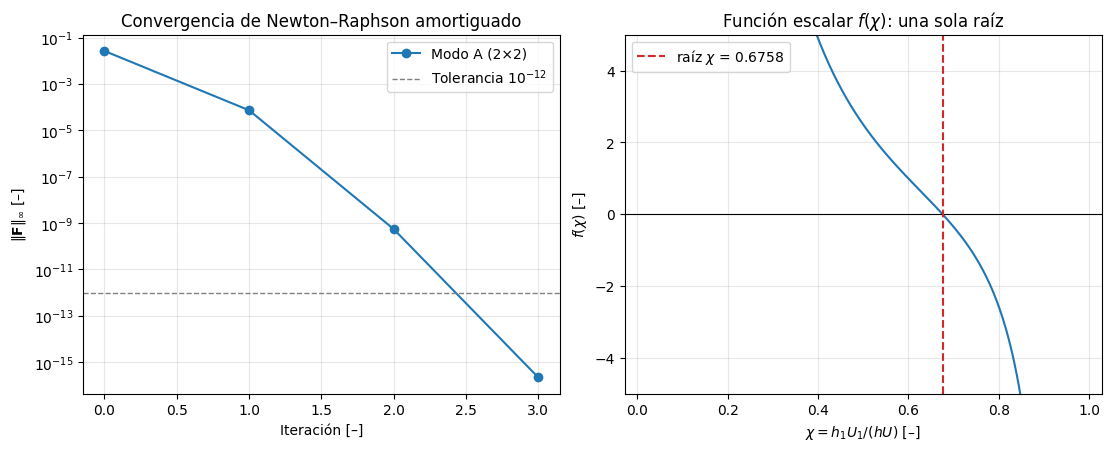

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")

ax = axs[0]
ax.semilogy(tabla_A["Iteración"], tabla_A["‖F‖∞"], "o-", label="Modo A (2×2)")
ax.axhline(1e-12, color="gray", ls="--", lw=1, label="Tolerancia $10^{-12}$")
ax.set_xlabel("Iteración [–]")
ax.set_ylabel(r"$\|\mathbf{F}\|_\infty$ [–]")
ax.set_title("Convergencia de Newton–Raphson amortiguado")
ax.grid(True, which="both", alpha=0.3); ax.legend()

ax = axs[1]
chis = np.linspace(0.02, 0.98, 400)
ax.plot(chis, [f_escalar(c, lam, mu, alpha) for c in chis], color="tab:blue")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(chi_A, color="tab:red", ls="--", label=fr"raíz $\chi$ = {chi_A:.4f}")
ax.set_ylim(-5, 5)
ax.set_xlabel(r"$\chi = h_1U_1/(hU)$ [–]")
ax.set_ylabel(r"$f(\chi)$ [–]")
ax.set_title(r"Función escalar $f(\chi)$: una sola raíz")
ax.grid(True, alpha=0.3); ax.legend()
plt.show()

## 13. Modo B: diseño del ancho del ramal (3×3) y comprobación analítica

Se pide que el ramal reciba $\varphi=0.30$ del caudal y se calcula el ancho relativo $\mu$ necesario con $\lambda=1$ y $\alpha=60^\circ$.

**Solución explícita para comparar.** Con $\mu u_2=\varphi$ y $\lambda u_1=1-\varphi$ en (7):

$$
\mu^{\pi/\alpha}\,\varphi^{\,1-\pi/\alpha}=\lambda^{\pi/\alpha}(1-\varphi)^{1-\pi/\alpha}-1
\quad\Longrightarrow\quad
\mu=\left[\frac{\lambda^{\pi/\alpha}(1-\varphi)^{1-\pi/\alpha}-1}{\varphi^{\,1-\pi/\alpha}}\right]^{\alpha/\pi}.
$$

Para que exista un $\mu>0$ debe cumplirse $\lambda^{\pi/\alpha}(1-\varphi)^{1-\pi/\alpha}>1$: **no cualquier fracción es alcanzable** si el canal principal aguas abajo es muy angosto.

In [10]:
def mu_explicito(lam, phi, alpha):
    """Solucion cerrada del modo B (None si la fraccion no es alcanzable)."""
    p = np.pi/alpha
    num = lam**p*(1 - phi)**(1 - p) - 1.0
    if num <= 0:
        return None
    return (num/phi**(1 - p))**(1/p)

phi = datos["phi_objetivo"]
FB = lambda x: F_diseno(x, lam, phi, alpha)
JB = lambda x: J_diseno(x, lam, phi, alpha)

x0_B = np.array([(1 - phi)/lam, phi/0.5, 0.5])          # semilla: mu = 0.5
x_B, tabla_B, ok_B = newton_amortiguado(FB, JB, x0_B)
mu_exacto = mu_explicito(lam, phi, alpha)

print("Convergió:", ok_B, f"({len(tabla_B)-1} iteraciones)")
print(f"μ (Newton 3×3)   = {x_B[2]:.12f}")
print(f"μ (explícito)    = {mu_exacto:.12f}")
print(f"h2 de diseño     = {x_B[2]*datos['h']:.4f} m  (h = {datos['h']} m)")
tabla_B_vis = tabla_B.rename(columns={"x1": "u1 [–]", "x2": "u2 [–]", "x3": "μ [–]"})
tabla_B_vis.style.format({"u1 [–]": "{:.8f}", "u2 [–]": "{:.8f}", "μ [–]": "{:.8f}",
                          "‖F‖∞": "{:.3e}", "λk (paso)": "{:.3g}"}).hide(axis="index")

Convergió: True (4 iteraciones)
μ (Newton 3×3)   = 0.454156500911
μ (explícito)    = 0.454156500911
h2 de diseño     = 1.8166 m  (h = 4.0 m)


Iteración,u1 [–],u2 [–],μ [–],‖F‖∞,λk (paso)
0,0.70000000,0.60000000,0.50000000,3.481e-01,nan
1,0.70000000,0.65012245,0.45823129,4.335e-02,1
2,0.70000000,0.66030962,0.45427122,1.069e-03,1
3,0.70000000,0.66056508,0.45415657,6.709e-07,1
4,0.70000000,0.66056524,0.45415650,2.685e-13,1


## 14. Verificación preliminar

Tres comprobaciones rápidas. **No sustituyen** a la verificación formal de la Fase II.

1. **Solución analítica en $\alpha=\pi/2$.** La ecuación (7) se vuelve cuadrática, $\chi^2-(1+\lambda^2+\mu^2)\chi+\lambda^2=0$, y la raíz admisible es $\chi=\tfrac12\left[(1+\lambda^2+\mu^2)-\sqrt{(1+\lambda^2+\mu^2)^2-4\lambda^2}\right]$. Con $\lambda=\mu=1$ da $(3-\sqrt5)/2$.
2. **Ida y vuelta entre modos:** el $\mu$ obtenido en el modo B, usado en el modo A, debe devolver la fracción $\varphi$.
3. **Continuidad:** $\lambda u_1+\mu u_2=1$ en la solución.

In [11]:
def chi_cuadratica(lam, mu):
    """alpha = pi/2: raiz admisible de chi^2 - (1+lam^2+mu^2) chi + lam^2 = 0."""
    s = 1 + lam**2 + mu**2
    return 0.5*(s - np.sqrt(s**2 - 4*lam**2))

pruebas = []
# 1) alpha = pi/2, dos casos analiticos, resueltos desde un arranque distinto al de 8 bisecciones
for (l_, m_) in [(1.0, 1.0), (0.7, 0.3)]:
    FA_ = lambda x, l_=l_, m_=m_: F_analisis(x, l_, m_, np.pi/2)
    JA_ = lambda x, l_=l_, m_=m_: J_analisis(x, l_, m_, np.pi/2)
    x_, _, ok_ = newton_amortiguado(FA_, JA_, valor_inicial(l_, m_, np.pi/2, n_pasos=3))
    esperado = chi_cuadratica(l_, m_)
    pruebas.append({"Prueba": f"1. α = π/2, λ = {l_}, μ = {m_}: χ", "Obtenido": l_*x_[0],
                    "Esperado": esperado, "Tolerancia": 1e-10})
# 2) ida y vuelta B -> A
FA_rt = lambda x: F_analisis(x, lam, x_B[2], alpha)
JA_rt = lambda x: J_analisis(x, lam, x_B[2], alpha)
x_rt, _, _ = newton_amortiguado(FA_rt, JA_rt, valor_inicial(lam, x_B[2], alpha))
pruebas.append({"Prueba": "2. Ida y vuelta: fracción al ramal", "Obtenido": x_B[2]*x_rt[1],
                "Esperado": phi, "Tolerancia": 1e-10})
pruebas.append({"Prueba": "2b. μ de Newton 3×3 vs explícito", "Obtenido": x_B[2],
                "Esperado": mu_exacto, "Tolerancia": 1e-10})
# 3) continuidad
pruebas.append({"Prueba": "3. Continuidad λ u1 + μ u2 (modo A)", "Obtenido": lam*u1_A + mu*u2_A,
                "Esperado": 1.0, "Tolerancia": 1e-12})
pruebas = pd.DataFrame(pruebas)
pruebas["|Obtenido − Esperado|"] = (pruebas["Obtenido"] - pruebas["Esperado"]).abs()
pruebas["¿Cumple?"] = pruebas["|Obtenido − Esperado|"] < pruebas["Tolerancia"]
pruebas.style.format({"Obtenido": "{:.12f}", "Esperado": "{:.12f}", "Tolerancia": "{:.0e}",
                      "|Obtenido − Esperado|": "{:.2e}"}).hide(axis="index")

Prueba,Obtenido,Esperado,Tolerancia,|Obtenido − Esperado|,¿Cumple?
"1. α = π/2, λ = 1.0, μ = 1.0: χ",0.381966011250,0.381966011250,1e-10,5.55e-17,True
"1. α = π/2, λ = 0.7, μ = 0.3: χ",0.423803331528,0.423803331528,1e-10,1.41e-13,True
2. Ida y vuelta: fracción al ramal,0.300000000000,0.300000000000,1e-10,1.50e-14,True
2b. μ de Newton 3×3 vs explícito,0.454156500911,0.454156500911,1e-10,2.77e-14,True
3. Continuidad λ u1 + μ u2 (modo A),1.000000000000,1.000000000000,1e-12,0.00e+00,True


## 15. Robustez del algoritmo y tabla de predicciones

Se resuelve el modo A para $\lambda=1$ (canal principal aguas abajo de igual ancho que aguas arriba), $\mu\in\{1.00,0.50,0.25\}$ y $\alpha\in\{30^\circ,45^\circ,60^\circ,90^\circ,120^\circ\}$. Esos valores corresponden a configuraciones estudiadas en la literatura (Gumgum, 2026) y a las que se simularán en 2D. Se compara el arranque por bisección con un arranque ingenuo ($u_1=u_2=1/(\lambda+\mu)$, velocidades iguales).

In [12]:
angulos = [30, 45, 60, 90, 120]
anchos = [1.00, 0.50, 0.25]
filas = []
for mu_i in anchos:
    for a_deg in angulos:
        a_ = np.radians(a_deg)
        FA_ = lambda x, m=mu_i, a=a_: F_analisis(x, 1.0, m, a)
        JA_ = lambda x, m=mu_i, a=a_: J_analisis(x, 1.0, m, a)
        x_b, t_b, ok_b = newton_amortiguado(FA_, JA_, valor_inicial(1.0, mu_i, a_))
        x_n, t_n, ok_n = newton_amortiguado(FA_, JA_, np.array([1/(1+mu_i)]*2))
        filas.append({"μ = Br [–]": mu_i, "α [°]": a_deg, "fracción al ramal 1−χ [–]": 1 - x_b[0],
                      "iter. (bisección)": len(t_b) - 1, "iter. (ingenuo)": len(t_n) - 1,
                      "convergen ambos": ok_b and ok_n,
                      "misma solución": abs(x_b[0] - x_n[0]) < 1e-9})
pred = pd.DataFrame(filas)
display(pred.style.format({"μ = Br [–]": "{:.2f}", "fracción al ramal 1−χ [–]": "{:.4f}"}).hide(axis="index"))
print("¿Todos convergen?", pred["convergen ambos"].all(), "| ¿Misma solución con ambos arranques?", pred["misma solución"].all())

μ = Br [–],α [°],fracción al ramal 1−χ [–],iter. (bisección),iter. (ingenuo),convergen ambos,misma solución
1.00,30,0.5016,2,2,True,True
1.00,45,0.5104,3,3,True,True
1.00,60,0.5310,3,3,True,True
1.00,90,0.6180,3,4,True,True
1.00,120,0.7800,3,6,True,True
0.50,30,0.3105,2,4,True,True
0.50,45,0.3116,3,4,True,True
0.50,60,0.3242,3,3,True,True
0.50,90,0.3904,2,3,True,True
0.50,120,0.5433,3,4,True,True


¿Todos convergen? True | ¿Misma solución con ambos arranques? True


## 16. Fracción al ramal frente al ángulo: contexto con una simulación publicada (ilustrativo)

Se superpone, **solo como contexto**, lo que reporta Gumgum (2026, *Appl. Sci.* 16, 3239) con simulaciones LES de 3D para $\lambda=1$, $Q_1=10$ L/s (Fig. 12 de ese artículo). Los puntos del artículo **se leyeron a ojo del gráfico** (error aproximado ±0.02) y corresponden a $Fr_1$ entre 0.2 y 0.6 con umbrales de fondo aguas abajo, de modo que no son una verificación del código. Para usarlos en el informe hay que pedir los datos al autor.

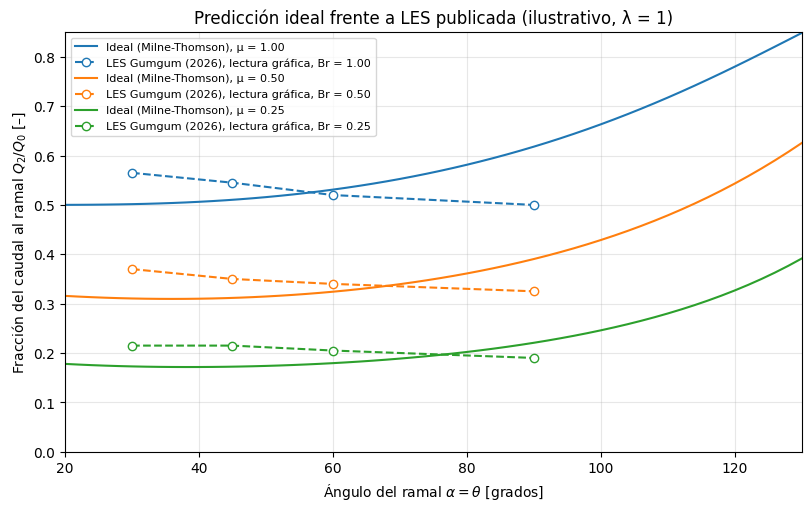

In [13]:
# Lectura grafica aproximada de la Fig. 12 de Gumgum (2026), Q1 = 10 L/s (±0.02). ILUSTRATIVO.
gumgum_aprox = {1.00: {30: 0.565, 45: 0.545, 60: 0.52, 90: 0.50},
                0.50: {30: 0.370, 45: 0.350, 60: 0.34, 90: 0.325},
                0.25: {30: 0.215, 45: 0.215, 60: 0.205, 90: 0.19}}
colores = {1.00: "tab:blue", 0.50: "tab:orange", 0.25: "tab:green"}

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
a_cont = np.linspace(20, 130, 56)
for mu_i in anchos:
    sol = []
    for a in a_cont:
        a_ = np.radians(a)
        F_ = lambda x, m=mu_i, a=a_: F_analisis(x, 1.0, m, a)
        J_ = lambda x, m=mu_i, a=a_: J_analisis(x, 1.0, m, a)
        x_, _, _ = newton_amortiguado(F_, J_, valor_inicial(1.0, mu_i, a_))
        sol.append(1 - x_[0])
    ax.plot(a_cont, sol, "-", color=colores[mu_i], label=f"Ideal (Milne-Thomson), μ = {mu_i:.2f}")
    angs = sorted(gumgum_aprox[mu_i])
    ax.plot(angs, [gumgum_aprox[mu_i][a] for a in angs], "o--", color=colores[mu_i], mfc="white",
            label=f"LES Gumgum (2026), lectura gráfica, Br = {mu_i:.2f}")
ax.set_xlabel(r"Ángulo del ramal $\alpha=\theta$ [grados]")
ax.set_ylabel(r"Fracción del caudal al ramal $Q_2/Q_0$ [–]")
ax.set_title("Predicción ideal frente a LES publicada (ilustrativo, λ = 1)")
ax.set_xlim(20, 130); ax.set_ylim(0, 0.85)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc="upper left", ncols=1)
plt.show()

## 17. Resumen de resultados

In [14]:
resumen = pd.DataFrame({
    "Variable": ["u1 = U1/U (modo A)", "u2 = U2/U (modo A)", "Fracción al ramal 1−χ (modo A)",
                 "μ de diseño para φ = 0.30 (modo B)", "h2 de diseño (modo B)",
                 "Iteraciones modo A", "Iteraciones modo B"],
    "Valor": [f"{u1_A:.6f}", f"{u2_A:.6f}", f"{1-chi_A:.6f}", f"{x_B[2]:.6f}",
              f"{x_B[2]*datos['h']:.4f}", str(len(tabla_A)-1), str(len(tabla_B)-1)],
    "Unidad": ["–", "–", "–", "–", "m", "–", "–"]})
display(resumen.style.hide(axis="index"))

Variable,Valor,Unidad
u1 = U1/U (modo A),0.675823,–
u2 = U2/U (modo A),0.648354,–
Fracción al ramal 1−χ (modo A),0.324177,–
μ de diseño para φ = 0.30 (modo B),0.454157,–
h2 de diseño (modo B),1.8166,m
Iteraciones modo A,3,–
Iteraciones modo B,4,–


## 18. Conclusiones de la Fase I y siguientes pasos

- La bifurcación ideal de Milne-Thomson se formuló como un sistema no lineal acoplado $2\times2$ (análisis) y $3\times3$ (diseño), con jacobiano analítico verificado contra diferencias finitas.
- La raíz admisible es **única** (demostración en la sección 8), y Newton amortiguado llega a ella con los dos arranques probados en las 15 configuraciones de la sección 15.
- El reparto depende **solo de $\lambda$, $\mu$ y $\alpha$**. El modelo no conoce el número de Froude, la rugosidad ni los controles aguas abajo.
- **El modo B tiene solución explícita** (sección 13); en esta formulación sirve de comprobación, y el problema de diseño genuinamente iterativo es el de la Formulación II.

**Hallazgo para la Discusión.** Con $\alpha=\theta$ y entre 30° y 90°, el modelo ideal da una fracción al ramal casi plana o **creciente** con el ángulo (de ≈ 0.50 a ≈ 0.62 con $\lambda=\mu=1$; para $\mu<1$ presenta un mínimo suave cerca de 40°), mientras que las simulaciones de Gumgum, leídas del gráfico, **decrecen** (≈ 0.565 a ≈ 0.50). El ideal además subestima a 30° y sobreestima a 90°, y la sobreestimación a 90° disminuye al estrechar el ramal. Las causas candidatas (separación en la esquina aguas arriba $E$, ausencia de control aguas abajo, tridimensionalidad) son hipótesis que el modelo 2D debe contrastar.

**Limitaciones de esta fase:** datos hipotéticos; modelo sin fricción ni separación; sin verificación formal (Fase II); la comparación de la sección 16 usa lecturas gráficas aproximadas.

**Fase II (siguiente):** las tres pruebas formales (solución analítica, caso publicado y propiedad matemática) con valor obtenido, esperado y tolerancia.